In [8]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd

madgraph_events = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold.h5")
sherpa_events = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_sherpa.h5")


In [10]:
import numpy as np #array manipulation
import tensorflow as tf #neural network library
from sklearn.model_selection import train_test_split #splits dataset into training set and test set
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

observables = ['pT_ll', 'pT_l1', 'pT_l2', 'eta_l1', 'eta_l2', 'phi_l1', 'phi_l2', 'y_ll', 'pT_trackj1', 'y_trackj1',
               'phi_trackj1', 'm_trackj1', 'tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'pT_trackj2', 'y_trackj2',
               'phi_trackj2', 'm_trackj2', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'Ntracks_trackj1', 
               'Ntracks_trackj2']


sherpa_features = sherpa_events[observables].values
madgraph_features = madgraph_events[observables].values

n_features = 24   # number of observables/columns you're using

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')   # sigmoid output -> probability between 0 and 1
])

def train_classifier(sherpa_features, madgraph_features, model, epochs=20, batch_size=10000): #feature events, 
    #each row is one event, each column is one observable
    # label = 1 for Sherpa, 0 for MadGraph

    scaler = StandardScaler()
    X_all = np.concatenate((sherpa_features, madgraph_features))
    scaler.fit(X_all)
    sherpa_features_scaled = scaler.transform(sherpa_features)
    madgraph_features_scaled = scaler.transform(madgraph_features)

    
    X = np.concatenate((sherpa_features_scaled, madgraph_features_scaled)) #stacks every Sherpa event on top of every MadGraph event
    #into one big array (full set of inputs network will see)
    y = np.concatenate((np.ones(len(sherpa_features)), np.zeros(len(madgraph_features)))) #creates corresponding truth
    #labels: 1 for every row coming from Sherpa, 0 for every row coming from MadGraph

    X_train, X_test, y_train, y_test = train_test_split(X, y) #default 75/25 train/test split

    model.compile(loss='binary_crossentropy',   # plain BCE -- no per-event weights needed 
                  #standard loss for 2-class problem (with sigmoid output)
                  #penalizes model based on how far its predicted probability was from the true label
                  #minimizing this loss is what makes model's output converge toward true probability that given event
                  #is sherpa vs Madgraph
                  optimizer='Adam', #algorithm that updates network's weights eaching training steo
                  metrics=['accuracy']) #if accuracy stays near 50%, both sims look statistically indistinguishable
    # if accuracy is well above 50%, there's real learnable structure differentiating them

    model.fit(X_train, y_train, #model runs through training data "epochs" times, updating weights via Adam to reduce
              #loss processing "batch_size" events at a time per gradient update
              epochs=epochs,
              batch_size=batch_size,
              validation_data=(X_test, y_test)) #evaluates loss/accuracy on test set without training on it
    #if training accuracy keeps climbing while validation accuracy plateaus or drops, that's overfitting warning sign

    history = model.fit(X_train, y_train,
                         epochs=epochs,
                         batch_size=batch_size,
                         validation_data=(X_test, y_test))
    return model, history, X_test, y_test

trained_model, history, X_test, y_test = train_classifier(sherpa_features, madgraph_features, model = model)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5853 - loss: 0.6726 - val_accuracy: 0.6078 - val_loss: 0.6591
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6122 - loss: 0.6556 - val_accuracy: 0.6198 - val_loss: 0.6498
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6213 - loss: 0.6483 - val_accuracy: 0.6268 - val_loss: 0.6439
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6258 - loss: 0.6439 - val_accuracy: 0.6303 - val_loss: 0.6409
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6299 - loss: 0.6411 - val_accuracy: 0.6325 - val_loss: 0.6390
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6314 - loss: 0.6395 - val_accuracy: 0.6338 - val_loss: 0.6375
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6331 - loss: 0.6381 - val_accuracy: 0.6356 - val_loss: 0.6368
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6344 - loss: 0.6370 - val_accuracy: 0.6363 - val_loss:

explain difference between plain BCE and weighted BCE

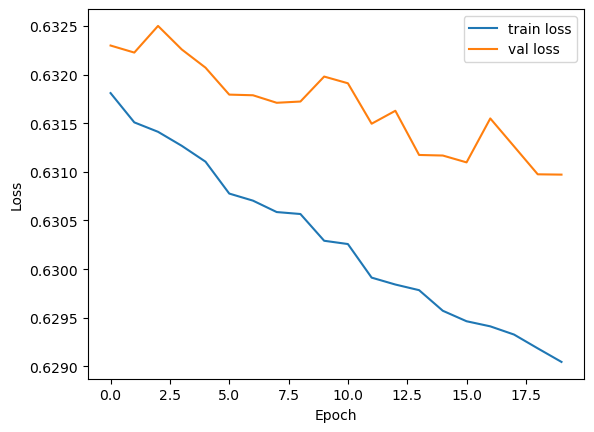

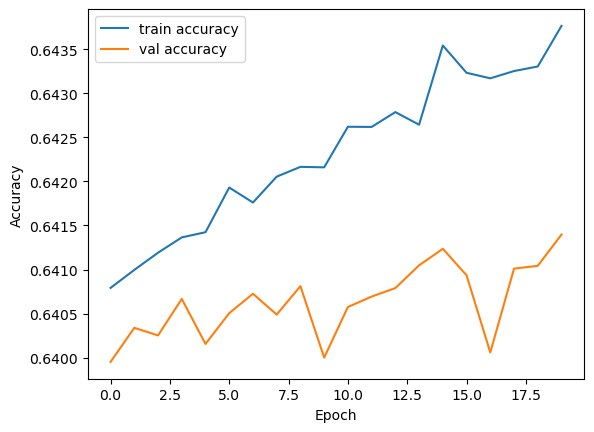

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

top panel: loss
- both train and validation loss decrease steadily and follow each other the whole way. this is GOOD --> no growing gap so network isnt overfitting, learning a generalizable pattern rather than memorization

bottom panel: accuracy
- curves climb, and plateaus, so network has essentially converged (running more epochs won't separate them more

  network has learned everything it's going to learn from these 24 observables using this architecture ~64% classification accuracy ceiling

5816/5816 ━━━━━━━━━━━━━━━━━━━━ 3s 482us/step


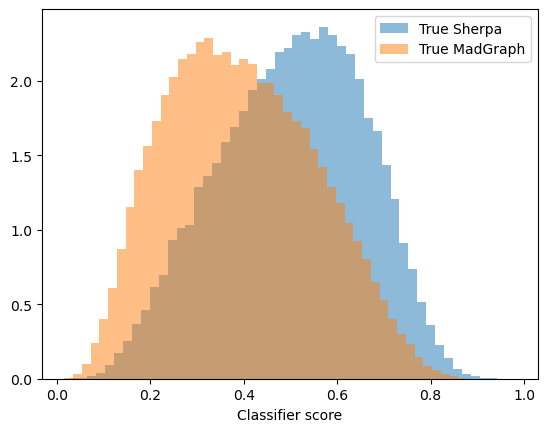

In [12]:
scores = trained_model.predict(X_test)

plt.hist(scores[y_test==1], bins=50, alpha=0.5, label='True Sherpa', density=True)
plt.hist(scores[y_test==0], bins=50, alpha=0.5, label='True MadGraph', density=True)
plt.xlabel('Classifier score'); plt.legend(); plt.show()

visualization of 64% accuracy, event-by-event
- true madgraph piles up more toward lower scores, peaking around 3.0
- true sherpa piles up more around higher scores, peaking around 0.55-0.6

substantial overlap, huge middle region where both populations have "real density" (around 0.3-0.7). 
    - sherpa and madgraphs are different implementations of the same physical process (different parton showers, matching schemes, etc.), so they should look similar in most events
    - classifier only confidently tells them apart in the tails where modeling differences are most pronounced.

if histogram showed two cleanly separated peaks near 0 and 1, with little overlap, that would show separation that model is "too-good-to-be-true" (eg. leaked identifying feature). 

AUC: 0.686


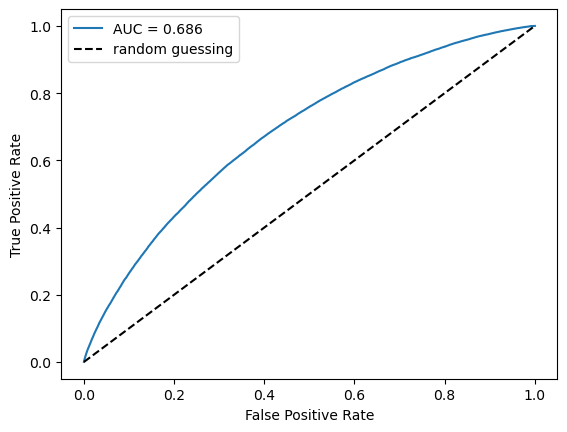

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve

auc = roc_auc_score(y_test, scores)
print(f"AUC: {auc:.3f}")

fpr, tpr, _ = roc_curve(y_test, scores) 
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1],'k--', label='random guessing')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.show()

AUC = 0.683 --> single number summary of everything above. (0.5 means classifier is no better than a coin flip, the diagonal line, and 1 means perfect separation)
    - confirms "overlapping but shifted" picture from image 2
    